In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [4]:
work_folder = 'edge_spen'
saving_folder = 'l7'
os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [6]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

In [7]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))
from ppo_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_ants = PPO_ants( env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)
        

In [8]:
load_from_run = True
ppo_ants.setup_networks()
best_weigths = False

if load_from_run and best_weigths:
    ppo_ants.load_weights(saving_folder + '/weights/best_weights')
else:
    if load_from_run:
        ppo_ants.load_weights(saving_folder + '/weights')
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/critic_weights.pth", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/actor_weights.pth", weights_only=True))

In [9]:
seed = int(saving_folder[-1])

In [10]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
n_special_list = [5,10,15,30,60]
n_seeds = 10

In [ ]:
import csv
import os
import numpy as np
import torch
import random

for n_special in n_special_list:

    for seed in range(n_seeds):
        
        saving_folder = 'l' + str(seed)

        env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                    tmax, n_special, t_transient, vision=state_dim[-1])
                
        ppo_ants = PPO_ants( env,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)

        ppo_ants.setup_networks()
        ppo_ants.load_weights(saving_folder + '/weights')

        filename = "prova.csv"

        # Intestazioni delle colonne
        header = [
            "seed", "sim_seed", "n_special", "beta", "delta",
            "pop",
            "pod",
            "rew_mean",
            "lastr_mean"
        ]

        # Se il file non esiste, scrivi l'header
        if not os.path.exists(filename):
            with open(filename, "w", newline="") as f:
                writer = csv.writer(f)
                writer.writerow(header)
        
        for i,beta in enumerate(beta_list):
            for j,delta in enumerate(delta_list):
                sim_seed = i*len(delta_list) + j
                np.random.seed(sim_seed)
                torch.manual_seed(sim_seed)
                random.seed(sim_seed)

                ppo_ants.env.reset_objects()
                ppo_ants.env.delta[:] = delta
                ppo_ants.env.beta[:] = beta
                
                ppo_ants.env.transient()

                results = ppo_ants.test_episode(max_prob=False, save_pos=True, reset=False)
                print(ppo_ants.env.delta[-1], ppo_ants.env.beta[-1], np.mean(results[0]))
                pop = ppo_ants.env.order_parameter_s()
                pod = ppo_ants.env.order_parameter_p()
                rew = np.mean(results[0])
                lastr = np.mean(np.array(results[0])[-50:])

                # Scriviamo direttamente nel CSV
                row_data = [
                    seed, sim_seed, n_special, beta, delta,
                    pop,  # std non calcolato singolo episodio
                    pod,
                    rew,
                    lastr
                ]

                with open(filename, "a", newline="") as f:
                    writer = csv.writer(f)
                    writer.writerow(row_data)

        print(f"Risultati salvati per seed {seed}")

0.3 3.5 -0.9604863220562556
0.4 3.5 -1.0792474292737781
0.3 4.5 -0.6875103800665722
0.4 4.5 -0.821237112859568
Risultati salvati per seed 0


In [11]:
# load the dataset
import pandas as pd
load = True
if load:
    dfbm = pd.read_csv("benchmark_results_bd.csv")

In [12]:
dfbm

,seed,sim_seed,n_special,beta,delta,pop,pod,rew_mean,lastr_mean
0,0,0,5,3.5,0.3,0.734811,0.260000,-1.031940,-0.897315
1,0,1,5,3.5,0.4,0.618158,0.333333,-1.186355,-1.172184
2,0,2,5,3.5,0.5,0.604989,0.166667,-1.176861,-1.189988
3,0,3,5,3.5,0.6,0.605549,0.160000,-1.196685,-1.166473
4,0,4,5,3.5,0.7,0.572753,0.100000,-1.238259,-1.267812
...,...,...,...,...,...,...,...,...,...
2095,9,37,60,9.5,0.4,0.997331,0.993333,-0.101342,-0.004294
2096,9,38,60,9.5,0.5,0.999994,1.000000,-0.036131,-0.000047
2097,9,39,60,9.5,0.6,0.999961,1.000000,-0.062979,-0.000812
2098,9,40,60,9.5,0.7,0.999921,1.000000,-0.077683,-0.013517


In [13]:
df=dfbm.groupby(['n_special']).agg(['mean', 'std']).drop(columns=['seed', 'sim_seed','beta', 'delta'])

In [14]:
df.style.format("{:.2f}")

In [21]:
dfbm_n30_0345 = dfbm[(dfbm['delta'] == 0.3) & (dfbm['beta'] == 4.5) & (dfbm['n_special'] == 30)]

In [22]:
dfbm_n30_0345

,seed,sim_seed,n_special,beta,delta,pop,pod,rew_mean,lastr_mean
1266,0,6,30,4.5,0.3,0.980227,0.960000,-0.233324,-0.114694
1308,1,6,30,4.5,0.3,0.995828,0.986667,-0.303146,-0.005753
1350,2,6,30,4.5,0.3,0.996408,0.966667,-0.099289,-0.006543
1392,3,6,30,4.5,0.3,0.929455,0.806667,-0.436886,-0.387145
1434,4,6,30,4.5,0.3,0.995795,0.980000,-0.279850,-0.013370
1476,5,6,30,4.5,0.3,0.996708,0.966667,-0.157724,-0.016271
1518,6,6,30,4.5,0.3,0.989197,0.880000,-0.147218,-0.054858
1560,7,6,30,4.5,0.3,0.967652,0.340000,-0.477254,-0.411581
1602,8,6,30,4.5,0.3,0.933247,0.900000,-0.407033,-0.149308
1644,9,6,30,4.5,0.3,0.998746,0.973333,-0.084043,-0.004437


In [14]:
raw_mean_df = dfbm.groupby(['n_special', 'beta', 'delta']).rew_mean.mean().unstack().unstack()
std_mean_df = dfbm.groupby(['n_special', 'beta', 'delta']).rew_mean.std().unstack().unstack()

raw_mean_df30 = raw_mean_df.loc[30]
std_mean_df30 = std_mean_df.loc[30]

raw_mean_arr30 = np.array(raw_mean_df30.values).reshape(len(delta_list), len(beta_list))
std_mean_arr30 = np.array(std_mean_df30.values).reshape(len(delta_list), len(beta_list))

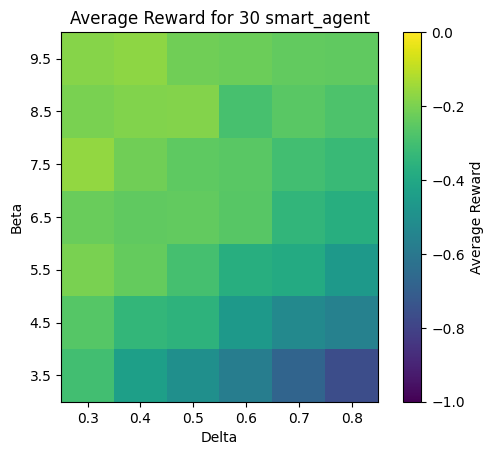

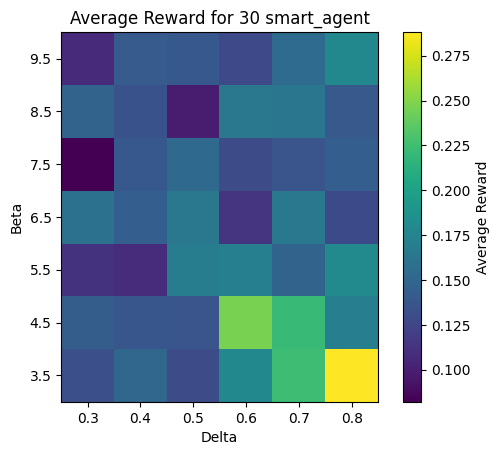

In [16]:
plt.imshow(raw_mean_arr30.T, cmap='viridis', origin='lower', vmin=-1, vmax=0)
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Reward for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

plt.imshow(std_mean_arr30.T, cmap='viridis', origin='lower')
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Reward for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()